# 01 — Does departure add predictive information?

**Question.** Compare profile alone, departure alone and their combination on identical risk sets.

In [1]:
from pathlib import Path
import sys
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'config/injury_profile_departure.yaml').exists())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from src.injury_analysis.profile_departure import inputs,read_table,OUT
from src.injury_analysis.profile_workflow import ensure_stage
from src.injury_analysis import profile_plots as plots
FORCE_RECOMPUTE=False
a,events,spec,matches=inputs()
pd.set_option('display.max_columns',16)


## Design and meanings
Reuse the existing 30-day injury targets, starters and relievers, observed-follow-up negatives, competing-injury exclusions, temporal partitions and 60-day embargo. Train through 2021; validate 2022–2023; evaluate the already examined 2024–2025 period. All preprocessing is learned on training rows.

**P:** eight strictly prior baseline means plus five slowly changing context fields. Baselines use at most 20 prior outings, minimum five valid measurements, and exclude the current date. They are evolving profiles, not lifetime traits.
**D:** the corresponding eight current pitcher z-scores. These become observable after the current outing; each includes the prior SD denominator.
**C:** 15 workload fields, current starter role and month, held common in adjusted comparisons because they mix persistent and situational information.

Use the existing median + missing-indicator + scaling + L2 logistic framework (C=1), with numerical tolerance 1e-9. Compare P, D, P+D; C+P, C+D, C+P+D; P+D plus eight prior slopes; workload/history; and the original 62 features. No field from future injury/activation outcomes enters a predictor. NULLs remain unchanged in source data. Arm angle is omitted for long-history availability.

In [2]:
ensure_stage('models',a,events,spec,matches,force=FORCE_RECOMPUTE)
display(read_table('model_specifications'))
display(read_table('cohort_counts'))
display(read_table('feature_definitions'))

Using verified models results (19 artifacts).


,variant,features,columns
0,Profile only,13,avg_fb_velo_baseline_mean;release_x_avg_baseli...
1,Departure only,8,velo_z;release_x_z;release_z_z;release_x_sd_z;...
2,Profile + Departure,21,avg_fb_velo_baseline_mean;release_x_avg_baseli...
3,Context + Profile,30,total_pitches;innings_pitched;rest_days;pitche...
4,Context + Departure,25,total_pitches;innings_pitched;rest_days;pitche...
5,Context + Profile + Departure,38,total_pitches;innings_pitched;rest_days;pitche...
6,Profile + Departure + slopes,29,avg_fb_velo_baseline_mean;release_x_avg_baseli...
7,Workload + history,22,total_pitches;innings_pitched;rest_days;pitche...
8,Original 62,62,avg_fb_velo;fb_velo_sd;fb_velo_change_vs_prev_...


,category,partition,rows,positive_rows,events,run
0,Elbow / UCL,train,81145,1441,223,True
1,Elbow / UCL,validation,26796,600,89,True
2,Elbow / UCL,test,27665,708,110,True
3,Shoulder,train,81978,2274,350,True
4,Shoulder,validation,26932,736,115,True
5,Shoulder,test,27806,849,125,True
6,Forearm,train,80362,658,109,True
7,Forearm,validation,26478,282,41,True
8,Forearm,test,27236,279,38,True
9,Other arm,train,80373,669,107,True


,feature,block,rationale,train_missing_fraction
0,acute_chronic_pitch_ratio,Shared workload/role/calendar adjustment,Mixed persistent and situational meaning; held...,0.020221
1,age_at_appearance,Profile: slowly changing context,"Age, handedness, observed experience or strict...",0.000000
2,appearances_prev_14d,Shared workload/role/calendar adjustment,Mixed persistent and situational meaning; held...,0.014471
3,appearances_prev_28d,Shared workload/role/calendar adjustment,Mixed persistent and situational meaning; held...,0.020221
4,avg_fb_velo,Original-model comparator only,"Absolute current measurements, raw pitch mix o...",0.007559
...,...,...,...,...
74,zone_pct,Original-model comparator only,"Absolute current measurements, raw pitch mix o...",0.000057
75,zone_pct_baseline_mean,Profile: prior measurement mean,"Up to 20 strictly prior outings, at least five...",0.000073
76,zone_pct_change_vs_prev_5,Original-model comparator only,"Absolute current measurements, raw pitch mix o...",0.000057
77,zone_pct_slope_prev_5,Secondary: prior trend,"Slope over up to five earlier outings, excludi...",0.000000


## Average Precision and incremental information
Intervals resample whole evaluation pitchers with shared draws across models (300 resamples). They condition on the fitted models and do not adjust across all categories or metrics. The black marks show prevalence; raw accuracy is not an outcome of interest. Positive rows and distinct represented events are reported separately.

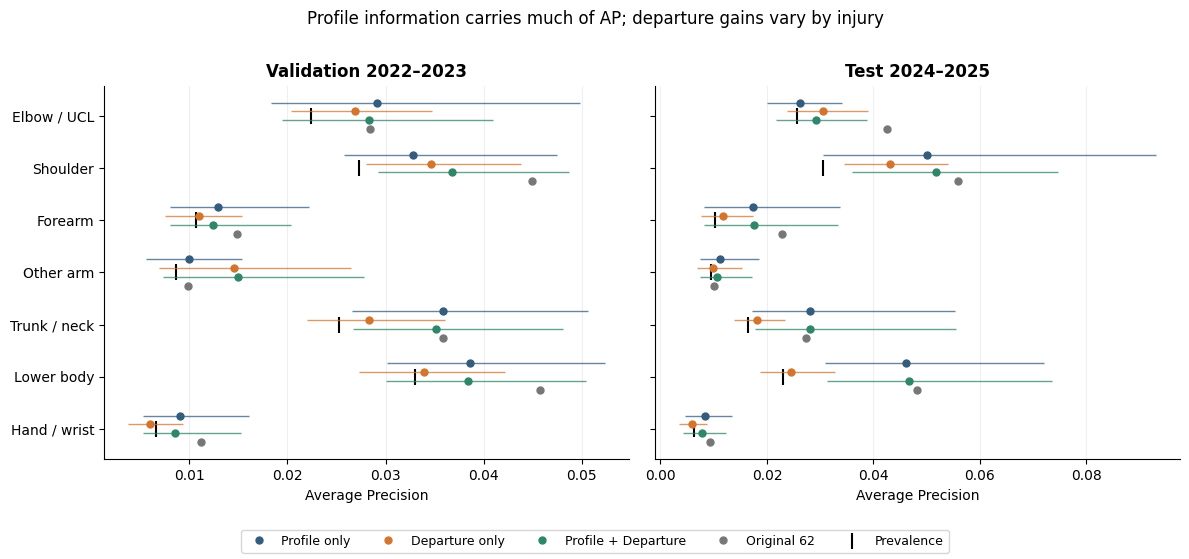

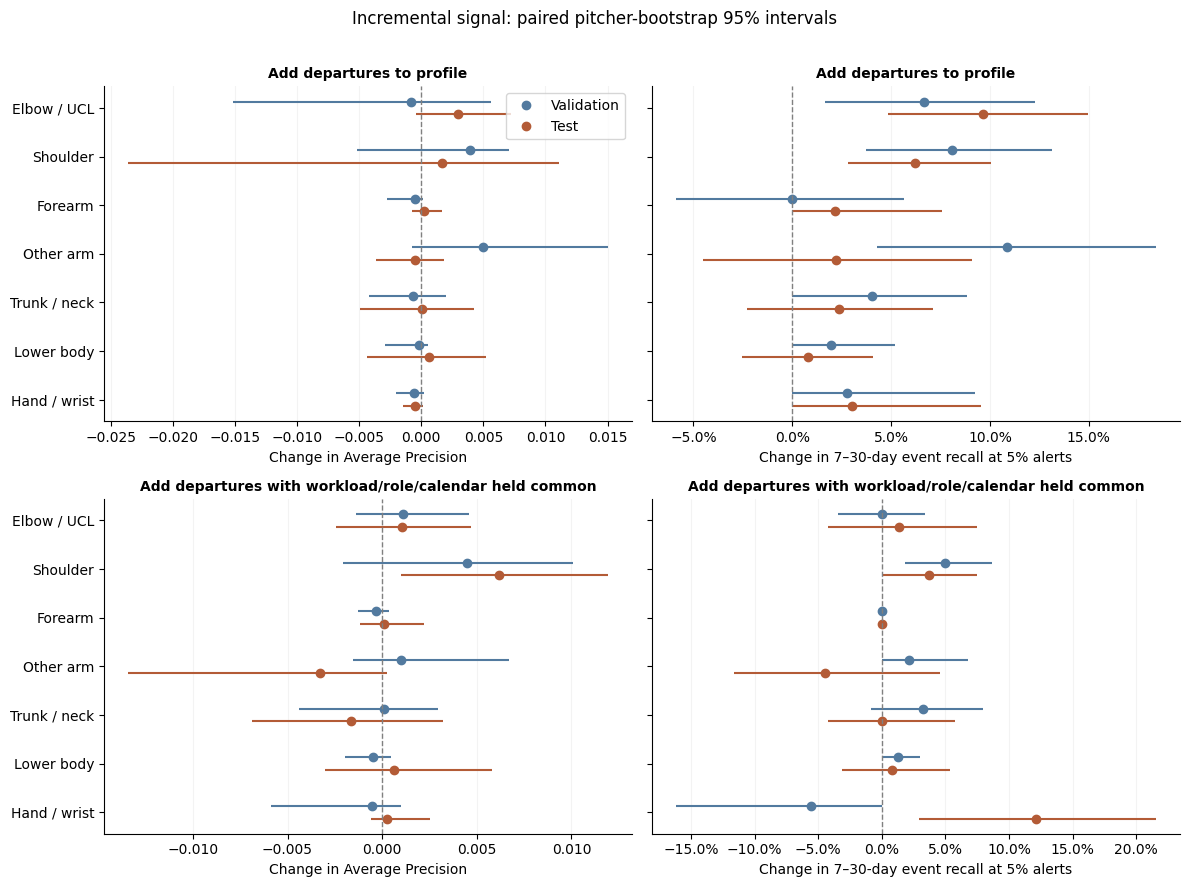

,category,partition,analysis,variant,reference,ap_difference,ap_low,ap_high,...,event_gained_events,event_lost_events,event_shared_detected_events,event_common_lead_mean,event_common_lead_low,event_common_lead_high,event_common_lead_events,event_common_lead_pitchers
0,Elbow / UCL,validation,Primary,Profile + Departure,Profile only,-0.000790,-0.015139,0.005600,...,9,1,8,0.625000,-2.000000,5.285714,8,6
2,Elbow / UCL,validation,Primary,Context + Profile + Departure,Context + Profile,0.001086,-0.001359,0.004600,...,3,3,13,1.384615,-0.307692,3.926923,13,13
5,Elbow / UCL,test,Primary,Profile + Departure,Profile only,0.002953,-0.000400,0.007185,...,16,2,2,-2.000000,-12.000000,8.000000,2,2
7,Elbow / UCL,test,Primary,Context + Profile + Departure,Context + Profile,0.001038,-0.002415,0.004701,...,8,6,24,-0.666667,-2.213089,1.000000,24,23
10,Shoulder,validation,Primary,Profile + Departure,Profile only,0.003902,-0.005145,0.007043,...,14,1,6,-1.333333,-3.087500,0.000000,6,6
12,Shoulder,validation,Primary,Context + Profile + Departure,Context + Profile,0.004460,-0.002087,0.010074,...,8,0,17,1.764706,-0.029167,4.452778,17,16
15,Shoulder,test,Primary,Profile + Departure,Profile only,0.001711,-0.023604,0.011088,...,10,0,15,-1.800000,-5.386859,1.853846,15,13
17,Shoulder,test,Primary,Context + Profile + Departure,Context + Profile,0.006191,0.001001,0.011924,...,9,3,21,0.000000,-0.842105,1.233158,21,19
20,Forearm,validation,Primary,Profile + Departure,Profile only,-0.000473,-0.002737,0.000156,...,1,1,4,0.000000,0.000000,0.000000,4,3
22,Forearm,validation,Primary,Context + Profile + Departure,Context + Profile,-0.000344,-0.001295,0.000352,...,0,0,7,-0.428571,-1.510714,0.000000,7,7


In [3]:
plots.performance_figure();plt.show()
plots.incremental_figure();plt.show()
display(read_table('incremental_comparisons').query("reference in ['Profile only','Context + Profile']"))

## Practical warnings and repeated alerts
The established warning window is 7–30 days, evaluated at 1%, 2.5%, 5% and 10% of eligible outings. All qualifying events remain in the denominator, including those without warning opportunities. Uniform-random expected recall accounts for each event's number of opportunities. Improving over a profile-only alert policy does not establish performance beyond random alerts.

Top-k budgets are retrospective. The separate validation-95th-percentile threshold table reports actual test alert rates. Warning lead comparisons among jointly detected events avoid confusing an altered detected-event mix with genuinely earlier warning.

Using verified scores results (9 artifacts).


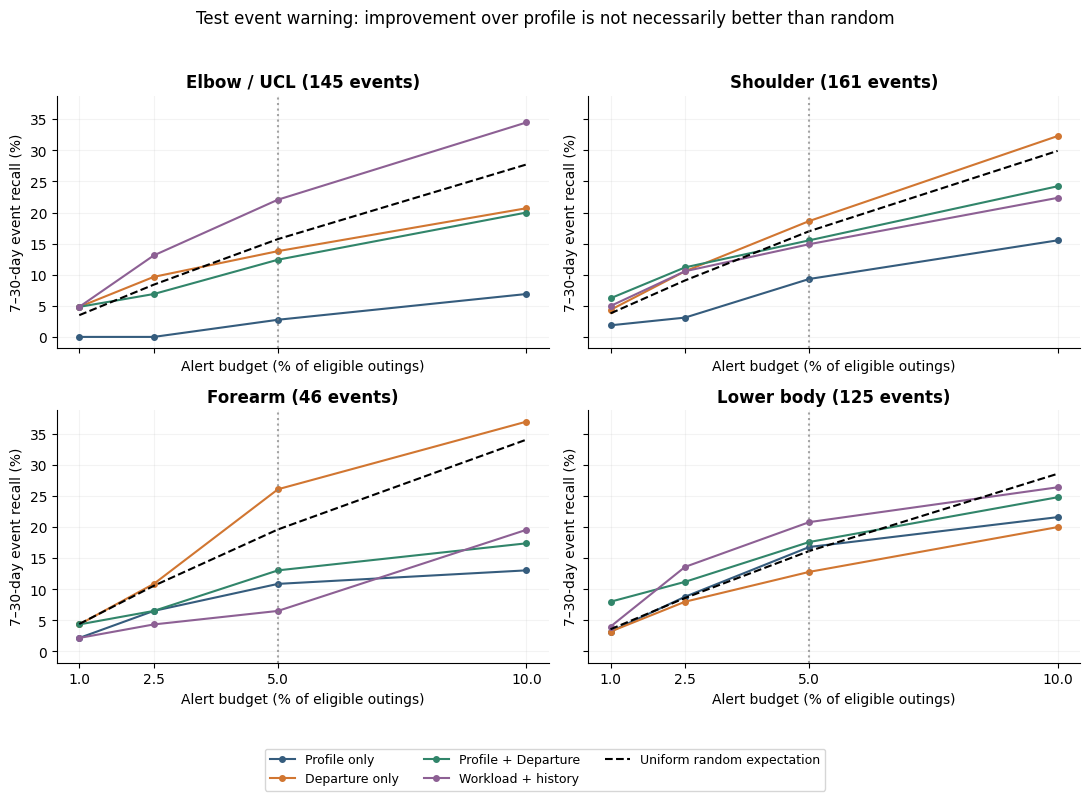

,average_precision,roc_auc,alert_rate,actual_alert_rate,rows,alerts,recall,precision,...,median_warning_lead_days,false_alerts_per_pitcher_season,non_actionable_alerts_per_pitcher_season,random_expected_event_recall,variant,category,partition,analysis
2,0.029100,0.519297,0.05,0.049970,26796,1339,0.110000,0.049291,...,24.0,1.052066,1.068595,0.155034,Profile only,Elbow / UCL,validation,Primary
6,0.026857,0.545011,0.05,0.049970,26796,1339,0.073333,0.032860,...,16.0,1.070248,1.085124,0.155034,Departure only,Elbow / UCL,validation,Primary
10,0.028310,0.545882,0.05,0.049970,26796,1339,0.086667,0.038835,...,24.0,1.063636,1.078512,0.155034,Profile + Departure,Elbow / UCL,validation,Primary
38,0.026197,0.522822,0.05,0.049991,27665,1383,0.014124,0.007231,...,10.5,1.147034,1.151211,0.157328,Profile only,Elbow / UCL,test,Primary
42,0.030564,0.555076,0.05,0.049991,27665,1383,0.066384,0.033984,...,22.5,1.116124,1.131161,0.157328,Departure only,Elbow / UCL,test,Primary
46,0.029149,0.545148,0.05,0.049991,27665,1383,0.055085,0.028200,...,18.0,1.122807,1.133668,0.157328,Profile + Departure,Elbow / UCL,test,Primary
74,0.032822,0.561839,0.05,0.049978,26932,1346,0.055707,0.030461,...,29.0,1.084788,1.091438,0.147642,Profile only,Shoulder,validation,Primary
78,0.034649,0.556728,0.05,0.049978,26932,1346,0.084239,0.046062,...,19.0,1.067332,1.088113,0.147642,Departure only,Shoulder,validation,Primary
82,0.036724,0.577013,0.05,0.049978,26932,1346,0.089674,0.049034,...,23.0,1.064007,1.078969,0.147642,Profile + Departure,Shoulder,validation,Primary
110,0.050124,0.573237,0.05,0.049989,27806,1390,0.115430,0.070504,...,27.0,1.083893,1.101510,0.169961,Profile only,Shoulder,test,Primary


,category,partition,variant,alerts,eligible_pitchers,alerted_pitchers,alerts_per_alerted_pitcher,fraction_alerts_top_ten_pitchers,median_alerted_outings_per_pitcher
0,Elbow / UCL,test,Profile only,1383,789,93,14.870968,0.389009,9.0
2,Elbow / UCL,test,Profile + Departure,1383,789,335,4.128358,0.195228,2.0
14,Forearm,test,Profile only,1361,779,61,22.311475,0.452608,14.0
16,Forearm,test,Profile + Departure,1361,779,100,13.610000,0.438648,6.0
28,Hand / wrist,test,Profile only,1356,779,53,25.584906,0.356932,25.0
30,Hand / wrist,test,Profile + Departure,1356,779,97,13.979381,0.342183,7.0
42,Lower body,test,Profile only,1379,783,54,25.537037,0.382161,21.5
44,Lower body,test,Profile + Departure,1379,783,97,14.216495,0.364757,6.0
56,Other arm,test,Profile only,1360,781,67,20.298507,0.359559,14.0
58,Other arm,test,Profile + Departure,1360,781,256,5.312500,0.248529,2.0


,category,variant,validation_threshold,validation_actual_rate,test_alert_rate,test_precision,test_recall,test_event_recall,median_warning_lead_days
0,Elbow / UCL,Profile only,0.031093,0.050007,0.039038,0.000926,0.001412,0.000000,NaN
1,Elbow / UCL,Departure only,0.026814,0.050007,0.045292,0.030327,0.053672,0.117241,25.0
2,Elbow / UCL,Profile + Departure,0.035759,0.050007,0.043087,0.024329,0.040960,0.103448,22.0
3,Elbow / UCL,Context + Profile,0.040564,0.050007,0.034159,0.057143,0.076271,0.158621,16.0
4,Elbow / UCL,Context + Departure,0.034118,0.050007,0.036761,0.066863,0.096045,0.165517,14.5
...,...,...,...,...,...,...,...,...,...
58,Hand / wrist,Context + Departure,0.020380,0.050017,0.041247,0.023235,0.151163,0.333333,20.0
59,Hand / wrist,Context + Profile + Departure,0.028881,0.050017,0.053559,0.016518,0.139535,0.303030,16.0
60,Hand / wrist,Profile + Departure + slopes,0.028857,0.050017,0.059420,0.005583,0.052326,0.090909,12.0
61,Hand / wrist,Workload + history,0.025289,0.050017,0.055697,0.016545,0.145349,0.272727,15.0


In [4]:
ensure_stage('scores',a,events,spec,matches,force=FORCE_RECOMPUTE)
plots.alert_figure();plt.show()
display(read_table('alert_budget_performance').query("alert_rate==0.05 and variant in ['Profile only','Departure only','Profile + Departure']"))
display(read_table('alert_concentration').query("partition=='test' and variant in ['Profile only','Profile + Departure']"))
display(read_table('validation_fixed_thresholds'))

## Probability quality
Brier loss measures total probability error, not calibration alone. Reliability bins use validation-score quantiles and the same fixed edges on test. These curves are descriptive; bin counts and positive support are saved. Mean bias and Brier differences complement them. No calibration map is fit here. Because follow-up requirements and competing events select the risk sets, estimated probabilities refer to this analysis cohort, not all MLB pitcher outings.

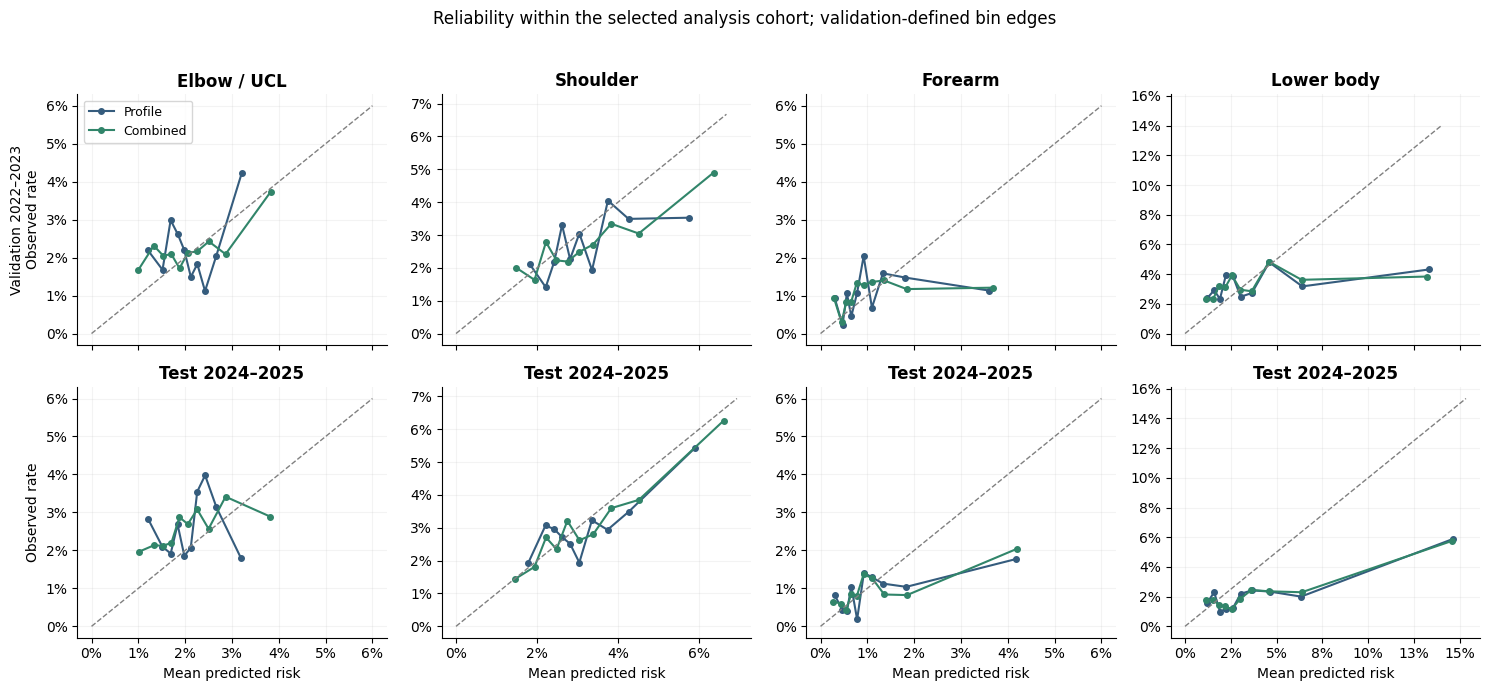

,category,partition,variant,rows,positive_rows,prevalence,average_precision,pr_lift,brier_score,calibration_bias
0,Elbow / UCL,validation,Profile only,26796,600,0.022391,0.029100,1.299596,0.021890,-0.001486
1,Elbow / UCL,validation,Departure only,26796,600,0.022391,0.026857,1.199421,0.021899,-0.004389
2,Elbow / UCL,validation,Profile + Departure,26796,600,0.022391,0.028310,1.264309,0.021887,-0.001439
9,Elbow / UCL,test,Profile only,27665,708,0.025592,0.026197,1.023639,0.024990,-0.005082
10,Elbow / UCL,test,Departure only,27665,708,0.025592,0.030564,1.194270,0.024980,-0.007763
11,Elbow / UCL,test,Profile + Departure,27665,708,0.025592,0.029149,1.139010,0.024977,-0.005273
18,Shoulder,validation,Profile only,26932,736,0.027328,0.032822,1.201041,0.026633,0.004722
19,Shoulder,validation,Departure only,26932,736,0.027328,0.034649,1.267875,0.026558,0.000672
20,Shoulder,validation,Profile + Departure,26932,736,0.027328,0.036724,1.343821,0.026604,0.004681
27,Shoulder,test,Profile only,27806,849,0.030533,0.050124,1.641621,0.029501,0.001713


,bin,rows,positive_rows,pitchers,mean_prediction,observed_rate,category,partition,variant
110,0,3264,64,388,0.010052,0.019608,Elbow / UCL,test,Profile + Departure
111,1,3046,65,477,0.013312,0.021339,Elbow / UCL,test,Profile + Departure
112,2,2827,60,528,0.015287,0.021224,Elbow / UCL,test,Profile + Departure
113,3,2955,65,571,0.017058,0.021997,Elbow / UCL,test,Profile + Departure
114,4,2750,79,577,0.018780,0.028727,Elbow / UCL,test,Profile + Departure
...,...,...,...,...,...,...,...,...,...
1195,5,2482,13,396,0.009010,0.005238,Hand / wrist,test,Profile + Departure
1196,6,2405,15,386,0.010555,0.006237,Hand / wrist,test,Profile + Departure
1197,7,2199,17,346,0.012854,0.007731,Hand / wrist,test,Profile + Departure
1198,8,2169,20,278,0.017124,0.009221,Hand / wrist,test,Profile + Departure


In [5]:
plots.calibration_figure();plt.show()
display(read_table('model_performance').query("variant in ['Profile only','Departure only','Profile + Departure']")[[
 'category','partition','variant','rows','positive_rows','prevalence','average_precision','pr_lift','brier_score','calibration_bias']])
display(read_table('reliability_bins').query("partition=='test' and variant=='Profile + Departure'"))

## Interpretation
Read the uncertainty on paired differences rather than treating every numerical increase as evidence. The workload-adjusted comparison answers a stricter question than P versus P+D. Continue to notebook 02 for within-pitcher score behavior, missingness and timing checks, and a computed synthesis.